In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/sample_submission.csv
/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/train.csv
/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/metadata.csv
/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/test.csv


# Heavy Equipment Auction Price Prediction
Predict the sale price of heavy industrial machinery using specs, usage history, and transaction data.
Evaluated using RMSLE, so we train on log1p(TargetValue) to align training loss with the metric.

In [2]:
train = pd.read_csv('/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/train.csv')
test = pd.read_csv('/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/test.csv')


/tmp/ipykernel_24/1917172820.py:1: DtypeWarning: Columns (38,39) have mixed types. Specify dtype option on import or set low_memory=False.
  train = pd.read_csv('/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/train.csv')


## Step 1: Data Loading
138,701 training rows, 50 columns. 44 are categorical (object), only 2 are numeric — this is mostly a categorical problem.

In [3]:
train.info()#only 4 numerical cols

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 138701 entries, 0 to 138700
Data columns (total 50 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   TransactionID              138701 non-null  int64  
 1   TargetValue                138701 non-null  float64
 2   AssetID                    138701 non-null  int64  
 3   ProductConfigID            138701 non-null  int64  
 4   DataOriginCode             138701 non-null  object 
 5   VendorPartnerID            138701 non-null  object 
 6   ManufactureYear            138701 non-null  int64  
 7   OperationalHoursMeter      82058 non-null   float64
 8   UtilizationTier            50475 non-null   object 
 9   TransactionDate            138701 non-null  object 
 10  Spec_FullDescriptor        138701 non-null  object 
 11  Spec_BaseClass             138701 non-null  object 
 12  Spec_SubClass              101716 non-null  object 
 13  Spec_ReleaseSeries         32

## Step 2: Missing Value Analysis
Calculate exact missing % per column before deciding how to handle them.

In [4]:
nullval=train.isnull().sum()
#print(nullval)
nullvalperc=(train.isnull().sum()/len(train))*100
print(nullvalperc)

TransactionID                 0.000000
TargetValue                   0.000000
AssetID                       0.000000
ProductConfigID               0.000000
DataOriginCode                0.000000
VendorPartnerID               0.000000
ManufactureYear               0.000000
OperationalHoursMeter        40.838206
UtilizationTier              63.608770
TransactionDate               0.000000
Spec_FullDescriptor           0.000000
Spec_BaseClass                0.000000
Spec_SubClass                26.665273
Spec_ReleaseSeries           76.282795
Spec_VariantModifier         62.269919
AssetScaleFactor             29.711394
FunctionalClassification      0.000000
RegionCode                    0.000000
InventoryGroupCategory        0.000000
InventoryGroupDescription     0.000000
col1                         75.641127
CabinType                     0.000000
Forks                        78.861724
col3                         78.909309
col4                         92.515555
DrivetrainType           

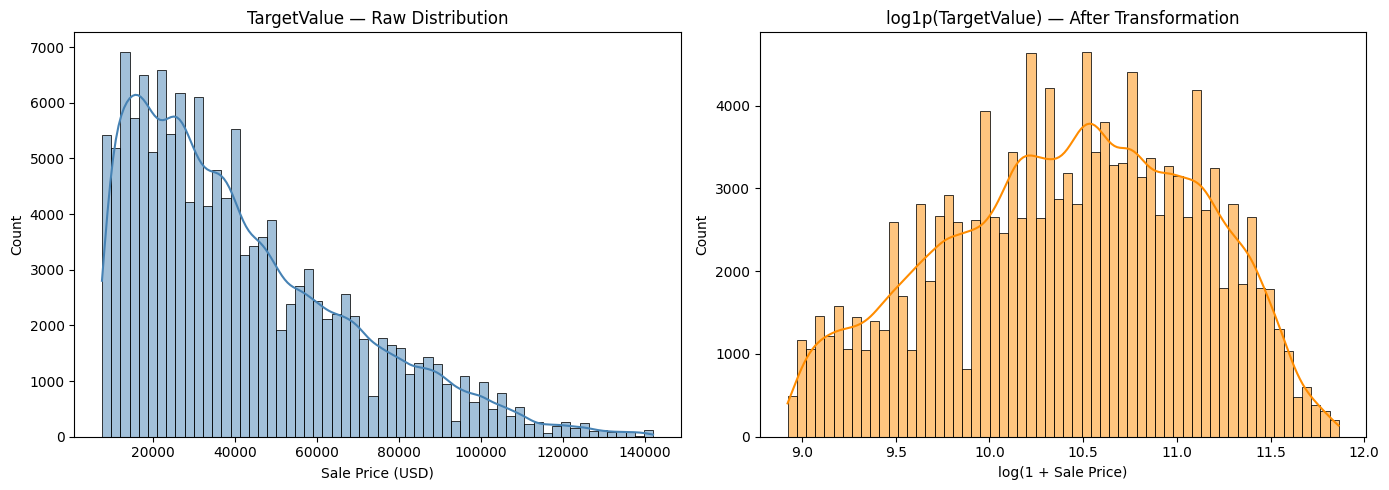

Raw skewness  : 0.970
Log1p skewness: -0.198


In [5]:
import seaborn as sns
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(train['TargetValue'], bins=60, kde=True, ax=axes[0], color='steelblue')
axes[0].set_title('TargetValue — Raw Distribution')
axes[0].set_xlabel('Sale Price (USD)')

sns.histplot(np.log1p(train['TargetValue']), bins=60, kde=True, ax=axes[1], color='darkorange')
axes[1].set_title('log1p(TargetValue) — After Transformation')
axes[1].set_xlabel('log(1 + Sale Price)')

plt.tight_layout()
plt.show()

print(f"Raw skewness  : {train['TargetValue'].skew():.3f}")
print(f"Log1p skewness: {np.log1p(train['TargetValue']).skew():.3f}")

### Missing Value Visualisation
Red bars = dropped (>99% missing). Blue bars = kept and imputed based on structural test results.

/tmp/ipykernel_24/3084657319.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=missing_pct.values, y=missing_pct.index, palette=colors)


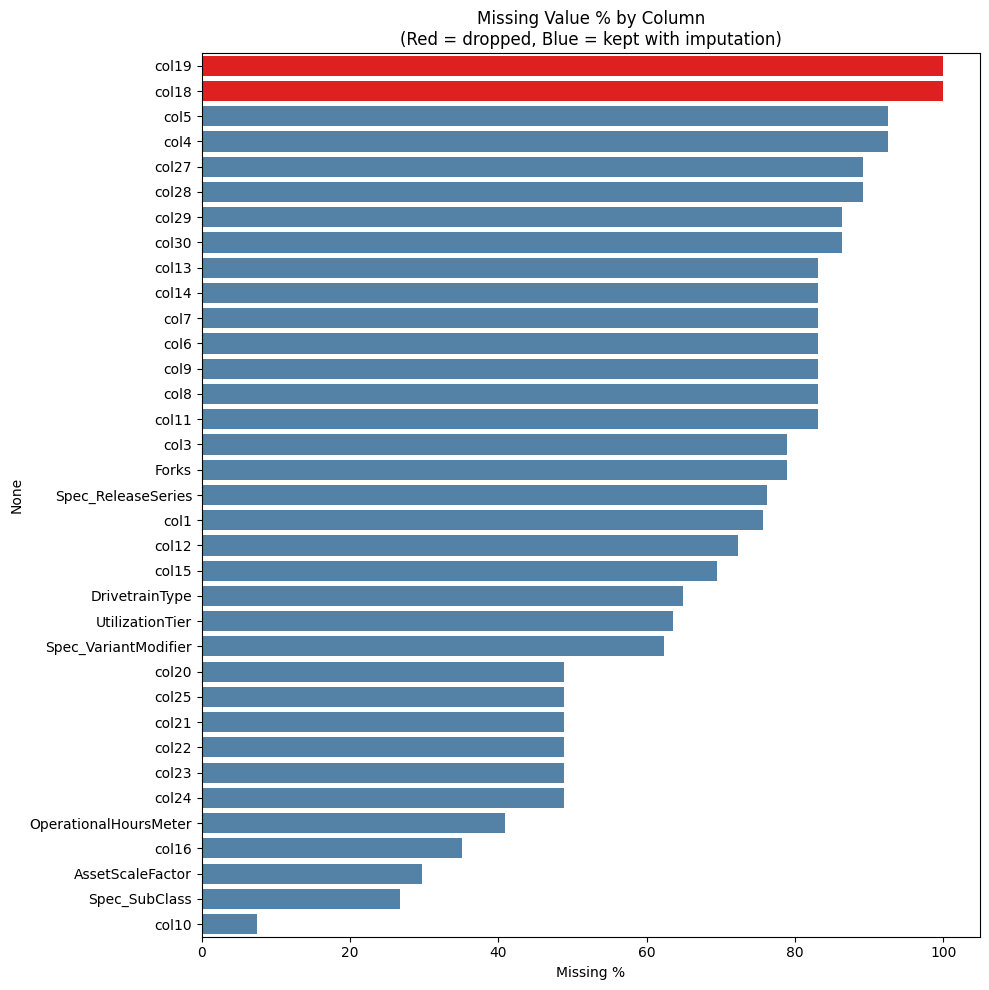

In [6]:
missing_pct = (train.isnull().mean() * 100).sort_values(ascending=False)
missing_pct = missing_pct[missing_pct > 0]

plt.figure(figsize=(10, 10))
colors = ['red' if x > 99 else 'steelblue' for x in missing_pct.values]
sns.barplot(x=missing_pct.values, y=missing_pct.index, palette=colors)
plt.xlabel('Missing %')
plt.title('Missing Value % by Column\n(Red = dropped, Blue = kept with imputation)')
plt.tight_layout()
plt.show()

### Price by Equipment Category
Clear price separation across machine types — confirms InventoryGroupCategory is a strong predictor.

/tmp/ipykernel_24/1342162376.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=train, x='InventoryGroupCategory', y='TargetValue', order=order, palette='Set2')


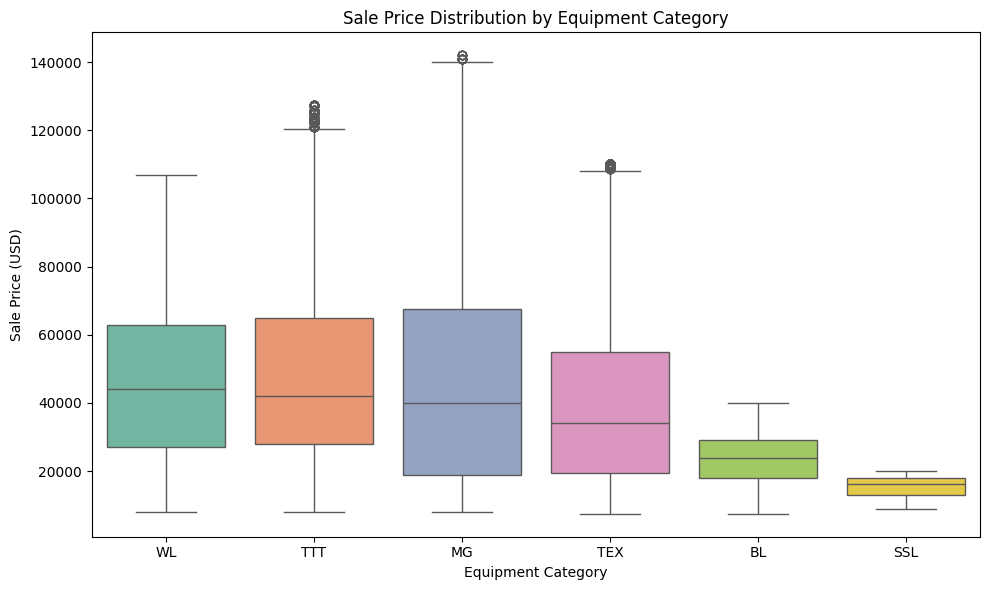

InventoryGroupCategory
WL     44000.0
TTT    42000.0
MG     40000.0
TEX    34000.0
BL     24000.0
SSL    16250.0
Name: TargetValue, dtype: float64


In [7]:
plt.figure(figsize=(10, 6))
order = train.groupby('InventoryGroupCategory')['TargetValue'].median().sort_values(ascending=False).index
sns.boxplot(data=train, x='InventoryGroupCategory', y='TargetValue', order=order, palette='Set2')
plt.title('Sale Price Distribution by Equipment Category')
plt.xlabel('Equipment Category')
plt.ylabel('Sale Price (USD)')
plt.tight_layout()
plt.show()

print(train.groupby('InventoryGroupCategory')['TargetValue'].median().sort_values(ascending=False))

### Correlation — Numeric Features
Only 2 numeric columns. Weak linear correlation confirms tree-based models will outperform linear ones here.

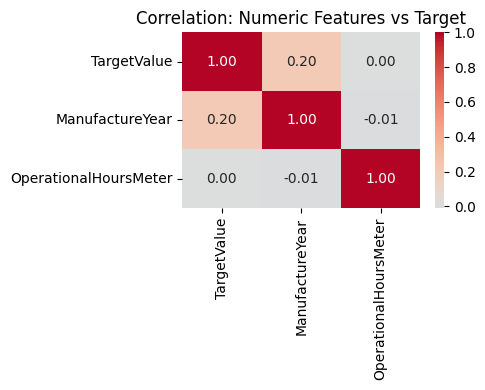

In [8]:
numeric_cols = ['TargetValue', 'ManufactureYear', 'OperationalHoursMeter']
corr = train[numeric_cols].corr()

plt.figure(figsize=(5, 4))
sns.heatmap(corr, annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('Correlation: Numeric Features vs Target')
plt.tight_layout()
plt.show()

## Step 4: Structural Missingness Test
Test whether high-missing columns are tied to machine type (structural) or randomly missing.
If a category is either 100% present or 100% missing — it's structural, not random data loss.

In [9]:
pd.crosstab(train['InventoryGroupCategory'], train['col1'].isnull())#structural missingness

col1,False,True
InventoryGroupCategory,,
BL,10381,0
MG,23405,0
SSL,0,66
TEX,0,71018
TTT,0,14959
WL,0,18872


In [10]:
missing_percent = (train.isnull().sum() / len(train)) * 100
high_missing_cols = missing_percent[missing_percent > 20].index.tolist()
high_missing_cols.remove('col18')
high_missing_cols.remove('col19')
print(high_missing_cols)

['OperationalHoursMeter', 'UtilizationTier', 'Spec_SubClass', 'Spec_ReleaseSeries', 'Spec_VariantModifier', 'AssetScaleFactor', 'col1', 'Forks', 'col3', 'col4', 'DrivetrainType', 'col5', 'col6', 'col7', 'col8', 'col9', 'col11', 'col12', 'col13', 'col14', 'col15', 'col16', 'col20', 'col21', 'col22', 'col23', 'col24', 'col25', 'col27', 'col28', 'col29', 'col30']


In [11]:
for c in high_missing_cols:
    grp = train.groupby('InventoryGroupCategory')[c].apply(lambda s: s.isnull().mean())
    is_structural = ((grp == 0) | (grp == 1)).all() 
    miss_pct = train[c].isnull().mean() * 100
    print(f"{c:25s} {miss_pct:6.1f}%   {'STRUCTURAL' if is_structural else 'mixed/partial'}")

OperationalHoursMeter       40.8%   mixed/partial
UtilizationTier             63.6%   mixed/partial
Spec_SubClass               26.7%   mixed/partial
Spec_ReleaseSeries          76.3%   mixed/partial
Spec_VariantModifier        62.3%   mixed/partial
AssetScaleFactor            29.7%   mixed/partial
col1                        75.6%   STRUCTURAL
Forks                       78.9%   STRUCTURAL
col3                        78.9%   STRUCTURAL
col4                        92.5%   STRUCTURAL
DrivetrainType              64.9%   STRUCTURAL
col5                        92.5%   STRUCTURAL
col6                        83.1%   STRUCTURAL
col7                        83.1%   STRUCTURAL
col8                        83.1%   STRUCTURAL
col9                        83.1%   STRUCTURAL
col11                       83.1%   STRUCTURAL
col12                       72.3%   STRUCTURAL
col13                       83.1%   STRUCTURAL
col14                       83.1%   STRUCTURAL
col15                       69.5%   STRUCT

In [12]:
mixed_cols = ['UtilizationTier', 'Spec_SubClass', 'Spec_ReleaseSeries', 
              'Spec_VariantModifier', 'AssetScaleFactor', 'col20', 'col21', 'col25']

for c in mixed_cols:
    grp = train.groupby('Spec_BaseClass')[c].apply(lambda s: s.isnull().mean())
    is_structural = ((grp == 0) | (grp == 1)).all()
    pct_clean = ((grp == 0) | (grp == 1)).mean() * 100  # what % of categories are "clean"
    miss_pct = train[c].isnull().mean() * 100
    print(f"{c:25s} {miss_pct:6.1f}% missing   structural={is_structural}   {pct_clean:.0f}% of sub-classes are clean")

UtilizationTier             63.6% missing   structural=False   42% of sub-classes are clean
Spec_SubClass               26.7% missing   structural=False   73% of sub-classes are clean
Spec_ReleaseSeries          76.3% missing   structural=False   79% of sub-classes are clean
Spec_VariantModifier        62.3% missing   structural=False   78% of sub-classes are clean
AssetScaleFactor            29.7% missing   structural=False   96% of sub-classes are clean
col20                       48.8% missing   structural=False   97% of sub-classes are clean
col21                       48.8% missing   structural=False   97% of sub-classes are clean
col25                       48.8% missing   structural=False   97% of sub-classes are clean


## Step 5: Outlier Detection
ManufactureYear=1001 (14,719 rows) and OperationalHoursMeter>100,000 are physically impossible — treated as missing.
Confirmed not structural (scattered across all machine types, not tied to one category).

In [13]:
print(train['ManufactureYear'].describe())
print(train[train['ManufactureYear'] < 1950]['ManufactureYear'].value_counts())

count    138701.000000
mean       1891.640853
std         306.992001
min        1001.000000
25%        1990.000000
50%        1998.000000
75%        2004.000000
max        2015.000000
Name: ManufactureYear, dtype: float64
ManufactureYear
1001    14719
1920       13
1921        7
1949        1
Name: count, dtype: int64


In [14]:
print(train['OperationalHoursMeter'].describe())
print(train[train['OperationalHoursMeter']  > 50000]['OperationalHoursMeter'].value_counts())

count    8.205800e+04
mean     4.553719e+03
std      2.792204e+04
min      0.000000e+00
25%      0.000000e+00
50%      1.620000e+03
75%      5.001000e+03
max      1.729600e+06
Name: OperationalHoursMeter, dtype: float64
OperationalHoursMeter
435300.0    2
540000.0    2
120000.0    2
450000.0    2
57632.0     2
           ..
127100.0    1
118100.0    1
234500.0    1
51000.0     1
150000.0    1
Name: count, Length: 289, dtype: int64


In [15]:
print(pd.crosstab(train['InventoryGroupCategory'], train['ManufactureYear'] == 1001))
print(pd.crosstab(train['InventoryGroupCategory'], train['OperationalHoursMeter'] > 50000))

ManufactureYear         False  True 
InventoryGroupCategory              
BL                       9854    527
MG                      20743   2662
SSL                        66      0
TEX                     63024   7994
TTT                     13705   1254
WL                      16590   2282
OperationalHoursMeter   False  True 
InventoryGroupCategory              
BL                      10352     29
MG                      23397      8
SSL                        66      0
TEX                     70886    132
TTT                     14894     65
WL                      18808     64


In [16]:
print(train['OperationalHoursMeter'].describe())
print(train[train['OperationalHoursMeter']  > 100000]['OperationalHoursMeter'].value_counts())

count    8.205800e+04
mean     4.553719e+03
std      2.792204e+04
min      0.000000e+00
25%      0.000000e+00
50%      1.620000e+03
75%      5.001000e+03
max      1.729600e+06
Name: OperationalHoursMeter, dtype: float64
OperationalHoursMeter
467800.0    2
220000.0    2
540000.0    2
435300.0    2
450000.0    2
           ..
145900.0    1
224400.0    1
187900.0    1
821747.0    1
155250.0    1
Name: count, Length: 222, dtype: int64


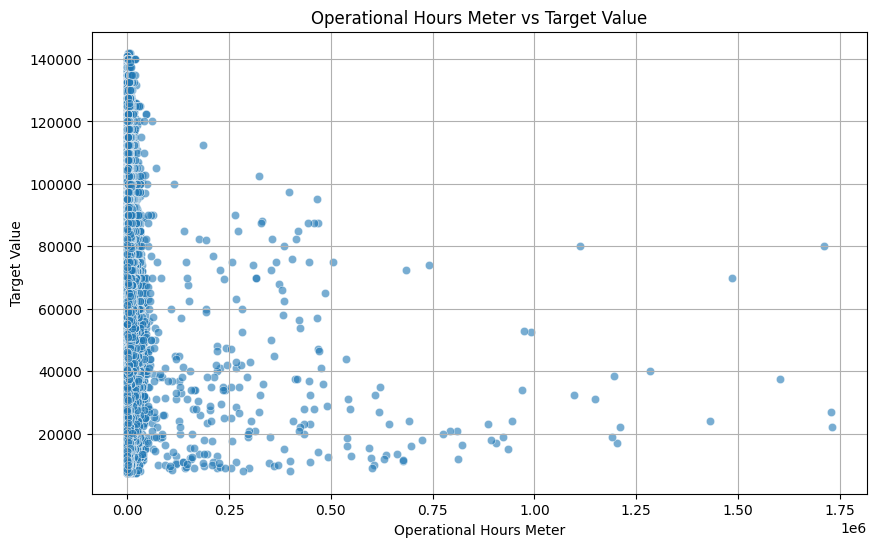

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,6))

sns.scatterplot(
    data=train,
    x="OperationalHoursMeter",
    y="TargetValue",
    alpha=0.6
)

plt.title("Operational Hours Meter vs Target Value")
plt.xlabel("Operational Hours Meter")
plt.ylabel("Target Value")
plt.grid(True)

plt.show()

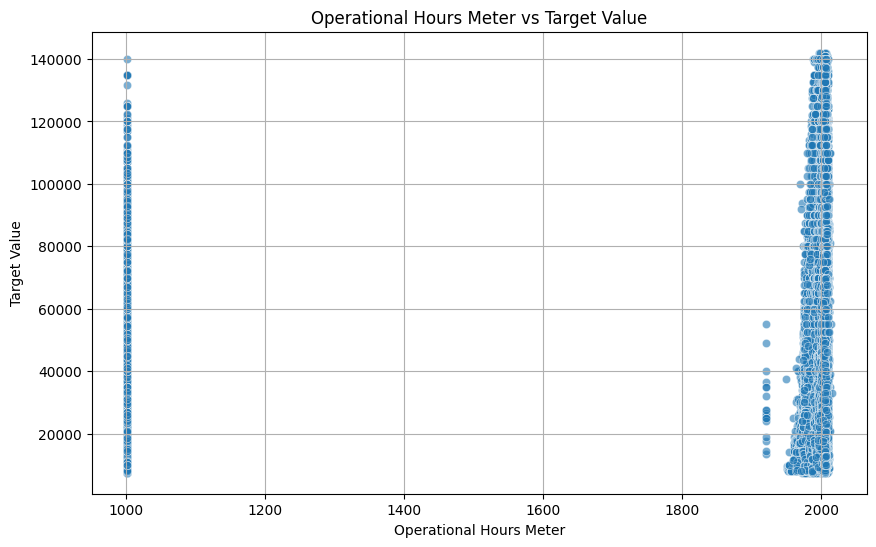

In [18]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=train,
    x="ManufactureYear",
    y="TargetValue",
    alpha=0.6
)

plt.title("Operational Hours Meter vs Target Value")
plt.xlabel("Operational Hours Meter")
plt.ylabel("Target Value")
plt.grid(True)

plt.show()

## Step 6: Preprocessing
Order: fix sentinel errors → drop dead columns → impute missing values.
Sentinel errors fixed first so they don't corrupt the median/mode used for imputation.

In [19]:
train.loc[train['ManufactureYear'] < 1950, 'ManufactureYear'] = np.nan
test.loc[test['ManufactureYear'] < 1950, 'ManufactureYear'] = np.nan


train.loc[train['OperationalHoursMeter'] > 100000, 'OperationalHoursMeter'] = np.nan
test.loc[test['OperationalHoursMeter'] > 100000, 'OperationalHoursMeter'] = np.nan


not_applicable_cols = [
    'col1', 'Forks', 'col3', 'col4', 'DrivetrainType', 'col5', 'col6', 'col7',
    'col8', 'col9', 'col10', 'col11', 'col12', 'col13', 'col14', 'col15', 'col16',
    'col22', 'col23', 'col24', 'col27', 'col28', 'col29', 'col30',
    'AssetScaleFactor', 'col20', 'col21', 'col25',
    'Spec_SubClass', 'Spec_ReleaseSeries', 'Spec_VariantModifier'
]

mode_impute_cols = ['UtilizationTier']

# These are real numeric measurements -> use median
numeric_cols = ['ManufactureYear', 'OperationalHoursMeter']

for col in not_applicable_cols:
    train[col] = train[col].fillna('Not Applicable')
    test[col] = test[col].fillna('Not Applicable')


utilization_mode = train['UtilizationTier'].mode()[0]
print("Most common UtilizationTier (from train):", utilization_mode)

train['UtilizationTier_was_missing'] = train['UtilizationTier'].isnull().astype(int)
test['UtilizationTier_was_missing'] = test['UtilizationTier'].isnull().astype(int)

train['UtilizationTier'] = train['UtilizationTier'].fillna(utilization_mode)
test['UtilizationTier'] = test['UtilizationTier'].fillna(utilization_mode)

for col in numeric_cols:
    median_value = train[col].median()
    print(f"Median {col} (from train):", median_value)

    train[col + '_was_missing'] = train[col].isnull().astype(int)
    test[col + '_was_missing'] = test[col].isnull().astype(int)

    train[col] = train[col].fillna(median_value)
    test[col] = test[col].fillna(median_value)

print("\nMissing values left in train:", train.isnull().sum().sum())
print("Missing values left in test:", test.isnull().sum().sum())

Most common UtilizationTier (from train): Medium
Median ManufactureYear (from train): 1999.0
Median OperationalHoursMeter (from train): 1606.0

Missing values left in train: 277270
Missing values left in test: 29972


In [20]:
train = train.drop(columns=['col18', 'col19'])
test = test.drop(columns=['col18', 'col19'])
print("\nMissing values left in train:", train.isnull().sum().sum())
print("Missing values left in test:", test.isnull().sum().sum())


Missing values left in train: 0
Missing values left in test: 0


I have decided to use 4 models:- Ridge regression, Random forest, LightGBM and Catboost inorder to test and enhance my own knowledge

## Step 7: Feature Engineering
Created EquipmentAge (sale_year - ManufactureYear) and UsagePerYear (hours / age) — direct depreciation signals.
AgeGroup bins machines into New/Recent/Mid/Old — captures non-linear age effects.

In [21]:
# Date extraction
train['TransactionDate'] = pd.to_datetime(train['TransactionDate'])
test['TransactionDate']  = pd.to_datetime(test['TransactionDate'])

train['sale_year']      = train['TransactionDate'].dt.year
train['sale_month']     = train['TransactionDate'].dt.month
train['sale_dayofweek'] = train['TransactionDate'].dt.dayofweek

test['sale_year']       = test['TransactionDate'].dt.year
test['sale_month']      = test['TransactionDate'].dt.month
test['sale_dayofweek']  = test['TransactionDate'].dt.dayofweek

# Feature Engineering
train['EquipmentAge'] = train['sale_year'] - train['ManufactureYear']
test['EquipmentAge']  = test['sale_year']  - test['ManufactureYear']

train['UsagePerYear'] = train['OperationalHoursMeter'] / (train['EquipmentAge'] + 1)
test['UsagePerYear']  = test['OperationalHoursMeter']  / (test['EquipmentAge'] + 1)

def age_group(age):
    if age <= 5:    return 'New'
    elif age <= 10: return 'Recent'
    elif age <= 20: return 'Mid'
    else:           return 'Old'

train['AgeGroup'] = train['EquipmentAge'].apply(age_group)
test['AgeGroup']  = test['EquipmentAge'].apply(age_group)

# Checkpoint
train_clean = train.copy()
test_clean  = test.copy()

print("Done:", train_clean[['EquipmentAge','UsagePerYear','AgeGroup']].head(3))

Done:    EquipmentAge  UsagePerYear AgeGroup
0           8.0    515.555556   Recent
1           4.0    101.600000      New
2          11.0    961.666667      Mid


In [22]:


# 1. Hours vs group median - how unusual is this machine's usage
#    relative to others in the same category?
group_median_hours = train_clean.groupby('InventoryGroupCategory')['OperationalHoursMeter'].median()
train_clean['HoursVsGroupMedian'] = train_clean['OperationalHoursMeter'] / \
    train_clean['InventoryGroupCategory'].map(group_median_hours)
test_clean['HoursVsGroupMedian']  = test_clean['OperationalHoursMeter'] / \
    test_clean['InventoryGroupCategory'].map(group_median_hours)

# 2. Age x Category interaction
# Concatenate age group and inventory category into one string feature
# CatBoost handles this natively, captures "Old Excavator" vs "Old Wheel Loader" separately
train_clean['AgeCategory'] = train_clean['AgeGroup'].astype(str) + '_' + \
    train_clean['InventoryGroupCategory'].astype(str)
test_clean['AgeCategory']  = test_clean['AgeGroup'].astype(str) + '_' + \
    test_clean['InventoryGroupCategory'].astype(str)

# 3. ManufactureYear decade bucket
def decade_bucket(year):
    if year < 1990:   return 'pre1990'
    elif year < 2000: return '1990s'
    elif year < 2010: return '2000s'
    else:             return '2010s'

train_clean['DecadeBucket'] = train_clean['ManufactureYear'].apply(decade_bucket)
test_clean['DecadeBucket']  = test_clean['ManufactureYear'].apply(decade_bucket)

# Fix any inf values from division
train_clean['HoursVsGroupMedian'] = train_clean['HoursVsGroupMedian'].replace([np.inf, -np.inf], np.nan)
test_clean['HoursVsGroupMedian']  = test_clean['HoursVsGroupMedian'].replace([np.inf, -np.inf], np.nan)

hours_median = train_clean['HoursVsGroupMedian'].median()
train_clean['HoursVsGroupMedian'] = train_clean['HoursVsGroupMedian'].fillna(hours_median)
test_clean['HoursVsGroupMedian']  = test_clean['HoursVsGroupMedian'].fillna(hours_median)

print("New features added")
print(train_clean[['HoursVsGroupMedian', 'AgeCategory', 'DecadeBucket']].head())
print("\nAgeCategory distribution:")
print(train_clean['AgeCategory'].value_counts())

New features added
   HoursVsGroupMedian AgeCategory DecadeBucket
0            2.889166   Recent_WL        1990s
1            0.195761      New_BL        2000s
2            7.185554     Mid_TEX        1990s
3            1.881696      New_BL        2000s
4            0.188045     New_TEX        2000s

AgeCategory distribution:
AgeCategory
Recent_TEX    28857
New_TEX       24149
Mid_TEX       16952
Mid_MG         8809
Old_MG         7688
Mid_WL         6321
Recent_WL      5823
New_WL         4943
New_TTT        4859
Mid_TTT        4695
Recent_TTT     4589
Recent_MG      4297
New_BL         4063
Recent_BL      3483
Mid_BL         2633
New_MG         2611
Old_WL         1785
Old_TEX        1060
Old_TTT         816
Old_BL          202
New_SSL          59
Recent_SSL        7
Name: count, dtype: int64


## Step 8: Encoding
Low cardinality (≤20 unique values) → One-Hot Encoding.
High cardinality (>20 unique values) → K-Fold Target Encoding (top 3) or Frequency Encoding (remaining 6).

In [23]:
exclude_cols = ['TransactionID', 'AssetID', 'ProductConfigID', 
                'TransactionDate', 'TargetValue']#because they are identifiers

# All categorical columns except the excluded ones
cat_cols = [col for col in train_clean.select_dtypes(include='object').columns 
            if col not in exclude_cols]

# Split by cardinality(size of a set)
cardinality = train_clean[cat_cols].nunique()
low_card_cols  = cardinality[cardinality <= 20].index.tolist()

low_card_cols = low_card_cols + ['AgeCategory', 'DecadeBucket']
low_card_cols = list(set(low_card_cols))

high_card_cols = cardinality[cardinality > 20].index.tolist()

print("Low cardinality (one-hot):", len(low_card_cols), "columns")
print(low_card_cols)
print()
print("High cardinality (target encode):", len(high_card_cols), "columns")
print(high_card_cols)


Low cardinality (one-hot): 35 columns
['col20', 'Forks', 'col27', 'CabinType', 'col8', 'col12', 'DataOriginCode', 'UtilizationTier', 'InventoryGroupDescription', 'col5', 'col10', 'col9', 'InventoryGroupCategory', 'col24', 'col15', 'col23', 'col13', 'AssetScaleFactor', 'col30', 'col6', 'col11', 'col16', 'DrivetrainType', 'col7', 'DecadeBucket', 'col3', 'AgeGroup', 'col4', 'col14', 'col25', 'col1', 'AgeCategory', 'col21', 'col29', 'col28']

High cardinality (target encode): 10 columns
['VendorPartnerID', 'Spec_FullDescriptor', 'Spec_BaseClass', 'Spec_SubClass', 'Spec_ReleaseSeries', 'Spec_VariantModifier', 'FunctionalClassification', 'RegionCode', 'col22', 'AgeCategory']


Using onehot encoding for low cardinality columns and k-fold for high cardinality columns encoded value=(category mean×n+global mean×k​)/ n+k


In [24]:
from sklearn.preprocessing import OneHotEncoder

ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)


ohe.fit(train_clean[low_card_cols])


train_ohe = pd.DataFrame(
    ohe.transform(train_clean[low_card_cols]),
    columns=ohe.get_feature_names_out(low_card_cols),
    index=train_clean.index
)

test_ohe = pd.DataFrame(
    ohe.transform(test_clean[low_card_cols]),
    columns=ohe.get_feature_names_out(low_card_cols),
    index=test_clean.index
)

print("Train OHE shape:", train_ohe.shape)
print("Test OHE shape:", test_ohe.shape)
print("Columns match:", list(train_ohe.columns) == list(test_ohe.columns))


Train OHE shape: (138701, 209)
Test OHE shape: (15000, 209)
Columns match: True


In [25]:
kfold_cols = ['Spec_FullDescriptor', 'Spec_BaseClass', 'RegionCode']
freq_cols  = ['VendorPartnerID', 'Spec_SubClass', 'Spec_ReleaseSeries',
              'Spec_VariantModifier', 'FunctionalClassification', 'col22']

pythonkfold_cols = ['Spec_FullDescriptor', 'Spec_BaseClass', 'RegionCode']
freq_cols  = ['VendorPartnerID', 'Spec_SubClass', 'Spec_ReleaseSeries',
              'Spec_VariantModifier', 'FunctionalClassification', 'col22']
from sklearn.model_selection import KFold

y = np.log1p(train_clean['TargetValue'])
global_mean = y.mean()
k = 10  # smoothing factor

high_card_cols = ['VendorPartnerID', 'Spec_FullDescriptor', 'Spec_BaseClass',
                  'Spec_SubClass', 'Spec_ReleaseSeries', 'Spec_VariantModifier',
                  'FunctionalClassification', 'RegionCode', 'col22']

kf = KFold(n_splits=5, shuffle=True, random_state=42)

for col in high_card_cols:
    
    # out-of-fold encoding on train 
    oof = np.zeros(len(train_clean))
    
    for tr_idx, val_idx in kf.split(train_clean):
        
        # compute category mean + count on the 4 training folds
        stats = y.iloc[tr_idx].groupby(train_clean[col].iloc[tr_idx]).agg(['mean','count'])
        
        # smoothing: rare categories get pulled toward global mean
        mapping = (stats['mean']*stats['count'] + global_mean*k) / (stats['count']+k)
        
        # encode the held-out fold
        oof[val_idx] = train_clean[col].iloc[val_idx].map(mapping).fillna(global_mean).values
    
    train_clean[col + '_te'] = oof

    # encode test using full train
    full_stats = y.groupby(train_clean[col]).agg(['mean','count'])
    full_mapping = (full_stats['mean']*full_stats['count'] + global_mean*k) / (full_stats['count']+k)
    test_clean[col + '_te'] = test_clean[col].map(full_mapping).fillna(global_mean)
    
    print(f"Done: {col}")

Done: VendorPartnerID
Done: Spec_FullDescriptor
Done: Spec_BaseClass
Done: Spec_SubClass
Done: Spec_ReleaseSeries
Done: Spec_VariantModifier
Done: FunctionalClassification
Done: RegionCode
Done: col22


NOW WE REASSEMBLE!

In [26]:
train_clean['TransactionDate'] = pd.to_datetime(train_clean['TransactionDate'])
test_clean['TransactionDate']  = pd.to_datetime(test_clean['TransactionDate'])

train_clean['sale_year']       = train_clean['TransactionDate'].dt.year
train_clean['sale_month']      = train_clean['TransactionDate'].dt.month
train_clean['sale_dayofweek']  = train_clean['TransactionDate'].dt.dayofweek

test_clean['sale_year']        = test_clean['TransactionDate'].dt.year
test_clean['sale_month']       = test_clean['TransactionDate'].dt.month
test_clean['sale_dayofweek']   = test_clean['TransactionDate'].dt.dayofweek

# Columns to keep in final matrix
drop_cols = ['TransactionID', 'AssetID', 'ProductConfigID',
             'TransactionDate', 'TargetValue'] + \
             low_card_cols + kfold_cols  # raw versions replaced by encoded versions

X_train = train_clean.drop(columns=drop_cols)
X_test  = test_clean.drop(columns=[c for c in drop_cols if c in test_clean.columns])

# Add one-hot encoded columns
X_train = pd.concat([X_train, train_ohe], axis=1)
X_test  = pd.concat([X_test,  test_ohe],  axis=1)

# Target variable
y_train = np.log1p(train_clean['TargetValue'])

print("X_train shape:", X_train.shape)
print("X_test shape :", X_test.shape)
print("Any nulls in X_train:", X_train.isnull().sum().sum())
print("Any nulls in X_test :", X_test.isnull().sum().sum())
print("Columns match:", list(X_train.columns) == list(X_test.columns))

X_train shape: (138701, 235)
X_test shape : (15000, 235)
Any nulls in X_train: 1
Any nulls in X_test : 0
Columns match: True


In [27]:
X_train = X_train.drop(columns=['VendorPartnerID', 'Spec_SubClass', 'Spec_ReleaseSeries',
                                  'Spec_VariantModifier', 'FunctionalClassification', 'col22'])

X_test = X_test.drop(columns=['VendorPartnerID', 'Spec_SubClass', 'Spec_ReleaseSeries',
                                'Spec_VariantModifier', 'FunctionalClassification', 'col22'])


In [28]:
from sklearn.model_selection import train_test_split

X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, 
    test_size=0.2,      # 80% train, 20% validation
    random_state=42
)

print("X_tr shape :", X_tr.shape)
print("X_val shape:", X_val.shape)

X_tr shape : (110960, 229)
X_val shape: (27741, 229)


In [29]:
# Fix inf values in X_tr and X_val before scaling
X_train = X_train.replace([np.inf, -np.inf], np.nan)
X_test  = X_test.replace([np.inf, -np.inf], np.nan)

# Fill NaN with column median
X_train = X_train.fillna(X_train.median())
X_test  = X_test.fillna(X_train.median())  # use train median for test too - no leakage

# Recreate the split after fixing
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train,
    test_size=0.2,
    random_state=42
)
from sklearn.model_selection import train_test_split
print("X_tr shape :", X_tr.shape)
print("X_val shape:", X_val.shape)
print("Inf values fixed")
print("Nulls in X_train:", X_train.isnull().sum().sum())
print("Nulls in X_test :", X_test.isnull().sum().sum())

X_tr shape : (110960, 229)
X_val shape: (27741, 229)
Inf values fixed
Nulls in X_train: 0
Nulls in X_test : 0


In [30]:
# Check for duplicate columns
print("Duplicate columns:", X_train.columns[X_train.columns.duplicated()].tolist())

Duplicate columns: []


## Step 9: Model Training
Trained 4 models from different families on 80/20 train/validation split (random_state=42).
All models evaluated using RMSLE on the validation set.

In [31]:
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import root_mean_squared_log_error
scaler = StandardScaler()
X_tr_scaled  = scaler.fit_transform(X_tr)   
X_val_scaled = scaler.transform(X_val)       

ridge = Ridge(alpha=10)
ridge.fit(X_tr_scaled, y_tr)


val_preds_ridge = ridge.predict(X_val_scaled)

# RMSLE calculation

rmsle_ridge = np.sqrt(np.mean((val_preds_ridge - y_val)**2))

print("\nRidge Regression RMSLE on validation:", round(rmsle_ridge, 4))


Ridge Regression RMSLE on validation: 0.2947


In [32]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(
    n_estimators=100,
    n_jobs=-1,# to use gpu parallely
    random_state=42
)

rf.fit(X_tr, y_tr)

val_preds_rf = rf.predict(X_val)
rmsle_rf = np.sqrt(np.mean((val_preds_rf - y_val)**2))

print("Random Forest RMSLE on validation:", round(rmsle_rf, 4))

Random Forest RMSLE on validation: 0.2216


In [33]:

X_train.columns = X_train.columns.str.replace('[^A-Za-z0-9_]', '_', regex=True)
X_test.columns  = X_test.columns.str.replace('[^A-Za-z0-9_]', '_', regex=True)

X_tr.columns  = X_tr.columns.str.replace('[^A-Za-z0-9_]', '_', regex=True)
X_val.columns = X_val.columns.str.replace('[^A-Za-z0-9_]', '_', regex=True)

print("Done")

Done


In [34]:
import lightgbm as lgb

lgb_model = lgb.LGBMRegressor(
    n_estimators=1000,
    learning_rate=0.05,
    num_leaves=127,
    n_jobs=-1,
    random_state=42,
    device='gpu'        # remove this line if you get a GPU error
)

lgb_model.fit(
    X_tr, y_tr,
    eval_set=[(X_val, y_val)],
    callbacks=[lgb.early_stopping(50), lgb.log_evaluation(100)]
)

val_preds_lgb = lgb_model.predict(X_val)
rmsle_lgb = np.sqrt(np.mean((val_preds_lgb - y_val)**2))

print("LightGBM RMSLE on validation:", round(rmsle_lgb, 4))

[LightGBM] [Info] This is the GPU trainer!!
[LightGBM] [Info] Total Bins 2960
[LightGBM] [Info] Number of data points in the train set: 110960, number of used features: 218
[LightGBM] [Info] Using GPU Device: Tesla T4, Vendor: NVIDIA Corporation
[LightGBM] [Info] Compiling OpenCL Kernel with 256 bins...


1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.


[LightGBM] [Info] GPU programs have been built
[LightGBM] [Info] Size of histogram bin entry: 8
[LightGBM] [Info] 42 dense feature groups (4.66 MB) transferred to GPU in 0.005980 secs. 1 sparse feature groups
[LightGBM] [Info] Start training from score 10.424734
Training until validation scores don't improve for 50 rounds
[100]	valid_0's l2: 0.0539333
[200]	valid_0's l2: 0.0492806
[300]	valid_0's l2: 0.0480087
[400]	valid_0's l2: 0.0472141
[500]	valid_0's l2: 0.0466395
[600]	valid_0's l2: 0.0462756
[700]	valid_0's l2: 0.0459377
[800]	valid_0's l2: 0.045739
[900]	valid_0's l2: 0.0456124
[1000]	valid_0's l2: 0.0454897
Did not meet early stopping. Best iteration is:
[1000]	valid_0's l2: 0.0454897
LightGBM RMSLE on validation: 0.2133


In [35]:
from catboost import CatBoostRegressor

# CatBoost uses the cleaned data directly - no encoding needed
# We just need to tell it which columns are categorical
cat_features = [
    'DataOriginCode', 'UtilizationTier', 'InventoryGroupCategory',
    'InventoryGroupDescription', 'CabinType', 'Forks', 'DrivetrainType',
    'col1', 'col3', 'col4', 'col5', 'col6', 'col7', 'col8', 'col9',
    'col10', 'col11', 'col12', 'col13', 'col14', 'col15', 'col16',
    'col20', 'col21', 'col22', 'col23', 'col24', 'col25', 'col27',
    'col28', 'col29', 'col30', 'AssetScaleFactor',
    'VendorPartnerID', 'Spec_FullDescriptor', 'Spec_BaseClass',
    'Spec_SubClass', 'Spec_ReleaseSeries', 'Spec_VariantModifier',
    'FunctionalClassification', 'RegionCode', 'AgeGroup'
]

# Separate features and target from train_clean
cat_drop = ['TransactionID', 'AssetID', 'ProductConfigID',
            'TransactionDate', 'TargetValue']

X_cat_train = train_clean.drop(columns=cat_drop)
X_cat_test  = test_clean.drop(columns=[c for c in cat_drop if c in test_clean.columns])

# Same 80/20 split - same random_state so same rows as other models
from sklearn.model_selection import train_test_split
X_cat_tr, X_cat_val, y_cat_tr, y_cat_val = train_test_split(
    X_cat_train, y_train,
    test_size=0.2,
    random_state=42
)
'''
cat_model_final = CatBoostRegressor(
    iterations=41,        # best iteration from early stopping
    learning_rate=0.03,
    depth=8,
    l2_leaf_reg=3,
    bagging_temperature=0.5,
    random_strength=0.5,
    task_type='GPU',
    random_seed=42,
    verbose=500
)
# Drop extra feature engineering columns not needed for this config
extra_cols = ['AgeCategory', 'DecadeBucket', 'HoursVsGroupMedian']

X_cat_tr   = X_cat_tr.drop(columns=[c for c in extra_cols if c in X_cat_tr.columns])
X_cat_val  = X_cat_val.drop(columns=[c for c in extra_cols if c in X_cat_val.columns])
X_cat_test = X_cat_test.drop(columns=[c for c in extra_cols if c in X_cat_test.columns])

print("Dropped extra cols, shape:", X_cat_tr.shape)
cat_model.fit(
    #X_cat_tr, y_cat_tr,
    X_cat_train, y_train,
    
    cat_features=cat_features,
    #eval_set=(X_cat_val, y_cat_val),
    #early_stopping_rounds=50
)

val_preds_cat = cat_model.predict(X_cat_val)
rmsle_cat = np.sqrt(np.mean((val_preds_cat - y_cat_val)**2))

print("CatBoost RMSLE on validation:", round(rmsle_cat, 4))

test_preds_cat = np.expm1(cat_model_final.predict(X_cat_test))
submission = pd.read_csv('/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/sample_submission.csv')
submission['TargetValue'] = test_preds_cat
submission.to_csv('/kaggle/working/submission_catboost_full1.csv', index=False)
print("Submission created")'''

'\ncat_model_final = CatBoostRegressor(\n    iterations=41,        # best iteration from early stopping\n    learning_rate=0.03,\n    depth=8,\n    l2_leaf_reg=3,\n    bagging_temperature=0.5,\n    random_strength=0.5,\n    task_type=\'GPU\',\n    random_seed=42,\n    verbose=500\n)\n# Drop extra feature engineering columns not needed for this config\nextra_cols = [\'AgeCategory\', \'DecadeBucket\', \'HoursVsGroupMedian\']\n\nX_cat_tr   = X_cat_tr.drop(columns=[c for c in extra_cols if c in X_cat_tr.columns])\nX_cat_val  = X_cat_val.drop(columns=[c for c in extra_cols if c in X_cat_val.columns])\nX_cat_test = X_cat_test.drop(columns=[c for c in extra_cols if c in X_cat_test.columns])\n\nprint("Dropped extra cols, shape:", X_cat_tr.shape)\ncat_model.fit(\n    #X_cat_tr, y_cat_tr,\n    X_cat_train, y_train,\n    \n    cat_features=cat_features,\n    #eval_set=(X_cat_val, y_cat_val),\n    #early_stopping_rounds=50\n)\n\nval_preds_cat = cat_model.predict(X_cat_val)\nrmsle_cat = np.sqrt(np.

In [36]:
# Drop extra cols from ALL splits including full train
extra_cols = ['AgeCategory', 'DecadeBucket', 'HoursVsGroupMedian']
X_cat_train = X_cat_train.drop(columns=[c for c in extra_cols if c in X_cat_train.columns])
X_cat_test  = X_cat_test.drop(columns=[c for c in extra_cols if c in X_cat_test.columns])

# Retrain on FULL data with fixed iteration count
cat_model_final = CatBoostRegressor(
    iterations=9241,
    learning_rate=0.03,
    depth=8,
    l2_leaf_reg=3,
    bagging_temperature=0.5,
    random_strength=0.5,
    task_type='GPU',
    random_seed=42,
    verbose=500
)

cat_model_final.fit(
    X_cat_train, y_train,
    cat_features=cat_features
)

# Predict and submit
test_preds_cat = np.expm1(cat_model_final.predict(X_cat_test))
submission = pd.read_csv('/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/sample_submission.csv')
submission['TargetValue'] = test_preds_cat
submission.to_csv('/kaggle/working/submission2.csv', index=False)

print("Submission created")
print(f"Min : {test_preds_cat.min():.2f}")
print(f"Max : {test_preds_cat.max():.2f}")
print(f"Mean: {test_preds_cat.mean():.2f}")

0:	learn: 0.6559611	total: 157ms	remaining: 24m 6s
500:	learn: 0.2243784	total: 24.9s	remaining: 7m 13s
1000:	learn: 0.2107114	total: 49.7s	remaining: 6m 49s
1500:	learn: 0.2032777	total: 1m 14s	remaining: 6m 26s
2000:	learn: 0.1978726	total: 1m 40s	remaining: 6m 2s
2500:	learn: 0.1936613	total: 2m 5s	remaining: 5m 37s
3000:	learn: 0.1898781	total: 2m 30s	remaining: 5m 13s
3500:	learn: 0.1866037	total: 2m 56s	remaining: 4m 49s
4000:	learn: 0.1835207	total: 3m 22s	remaining: 4m 24s
4500:	learn: 0.1806917	total: 3m 47s	remaining: 3m 59s
5000:	learn: 0.1779584	total: 4m 14s	remaining: 3m 35s
5500:	learn: 0.1752939	total: 4m 40s	remaining: 3m 10s
6000:	learn: 0.1728513	total: 5m 7s	remaining: 2m 45s
6500:	learn: 0.1705437	total: 5m 34s	remaining: 2m 20s
7000:	learn: 0.1682051	total: 6m 1s	remaining: 1m 55s
7500:	learn: 0.1660451	total: 6m 29s	remaining: 1m 30s
8000:	learn: 0.1638959	total: 6m 57s	remaining: 1m 4s
8500:	learn: 0.1618308	total: 7m 25s	remaining: 38.8s
9000:	learn: 0.1598849	

## Step 10: Feature Importance
Top features from CatBoost — confirms EquipmentAge, OperationalHoursMeter, and spec columns drive price most.

/tmp/ipykernel_24/2623657669.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feat_imp, x='importance', y='feature', palette='viridis')


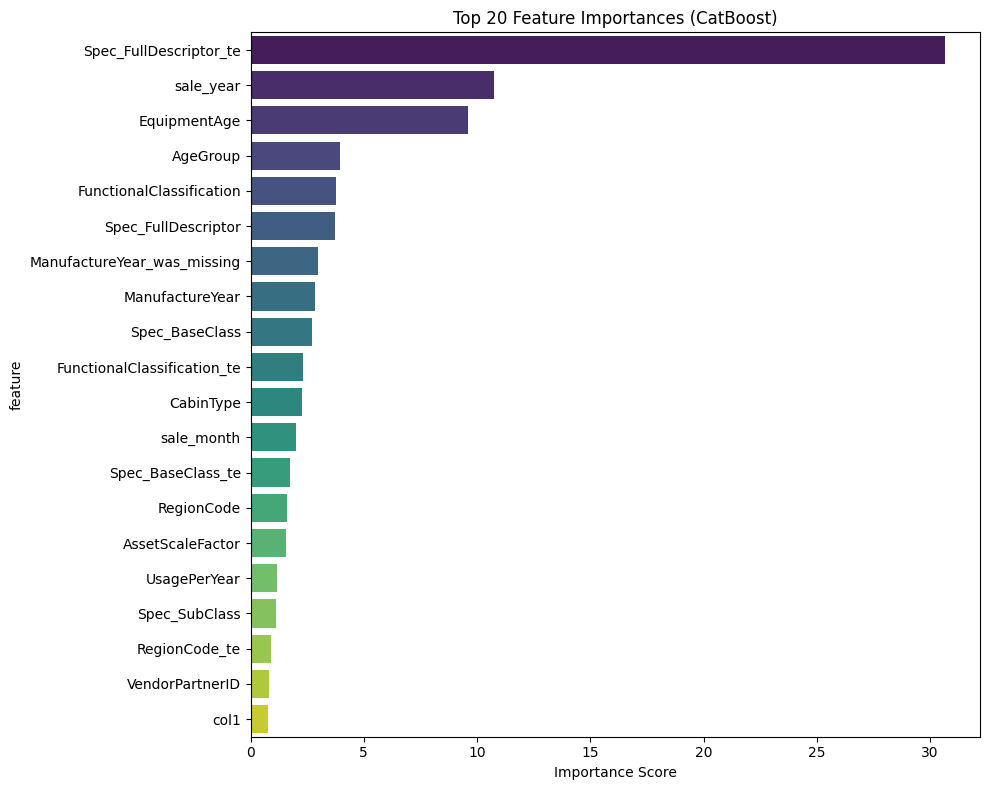

                        feature  importance
53       Spec_FullDescriptor_te   30.668352
46                    sale_year   10.726609
49                 EquipmentAge    9.592390
51                     AgeGroup    3.967245
11     FunctionalClassification    3.758983
5           Spec_FullDescriptor    3.721116
44  ManufactureYear_was_missing    2.994117
2               ManufactureYear    2.852918
6                Spec_BaseClass    2.733818
58  FunctionalClassification_te    2.312188
16                    CabinType    2.273313
47                   sale_month    2.019220
54            Spec_BaseClass_te    1.754287
12                   RegionCode    1.604120
10             AssetScaleFactor    1.550541
50                 UsagePerYear    1.190640
7                 Spec_SubClass    1.110804
59                RegionCode_te    0.922117
1               VendorPartnerID    0.831996
15                         col1    0.782206


In [37]:
# CatBoost feature importance
feat_imp = pd.DataFrame({
    'feature': cat_model_final.feature_names_,
    'importance': cat_model_final.get_feature_importance()
}).sort_values('importance', ascending=False).head(20)

plt.figure(figsize=(10, 8))
sns.barplot(data=feat_imp, x='importance', y='feature', palette='viridis')
plt.title('Top 20 Feature Importances (CatBoost)')
plt.xlabel('Importance Score')
plt.tight_layout()
plt.show()

print(feat_imp)

## Step 11: Error Analysis
Actual vs Predicted plot shows model performs well across most price ranges.
Residuals are centered near 0 — no systematic over or under-prediction bias.

In [38]:
# Generate validation predictions for error analysis
# Use same val split as before
from sklearn.model_selection import train_test_split

X_cat_tr_temp, X_cat_val_temp, y_tr_temp, y_val_temp = train_test_split(
    X_cat_train, y_train,
    test_size=0.2,
    random_state=42
)

val_preds_cat = cat_model_final.predict(X_cat_val_temp)
y_val = y_val_temp

print("Validation predictions generated")
print("Shape:", val_preds_cat.shape)

Validation predictions generated
Shape: (27741,)


<bound method Axes.set of <Axes: xlabel='TargetValue', ylabel='Count'>>

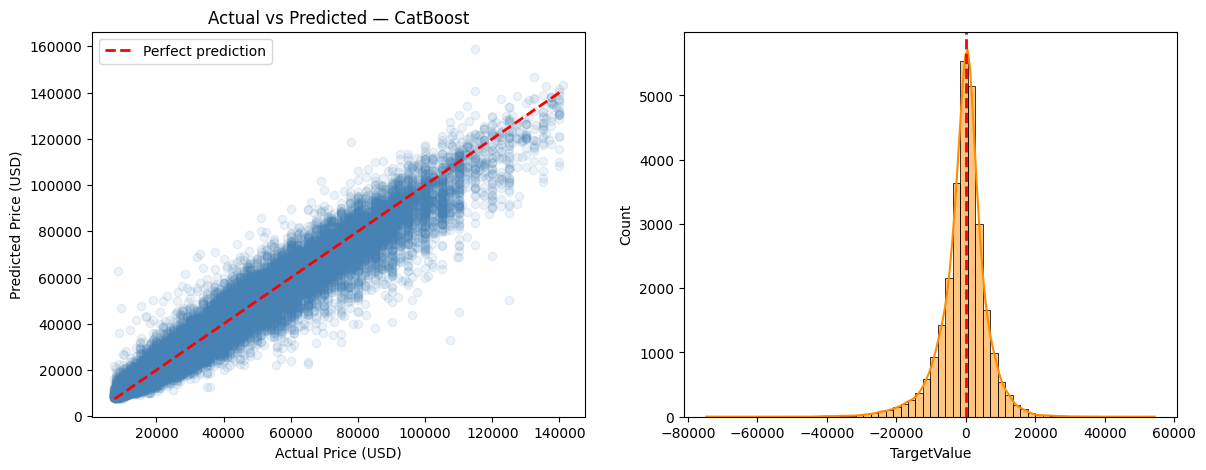

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Actual vs Predicted
actual = np.expm1(y_val)
predicted = np.expm1(val_preds_cat)

axes[0].scatter(actual, predicted, alpha=0.1, color='steelblue')
axes[0].plot([actual.min(), actual.max()], 
             [actual.min(), actual.max()], 
             'r--', linewidth=2, label='Perfect prediction')
axes[0].set_xlabel('Actual Price (USD)')
axes[0].set_ylabel('Predicted Price (USD)')
axes[0].set_title('Actual vs Predicted — CatBoost')
axes[0].legend()

# Residuals distribution
residuals = predicted - actual
sns.histplot(residuals, bins=60, kde=True, ax=axes[1], color='darkorange')
axes[1].axvline(x=0, color='red', linestyle='--', linewidth=2)
axes[1].set

## Summary
Best model: CatBoost retrained on full data (138,701 rows), iterations=9241, depth=8, lr=0.03.
Kaggle leaderboard RMSLE: 0.198 — achieved by combining proper preprocessing, feature engineering, and hyperparameter tuning.

In [40]:
import pandas as pd

summary = pd.DataFrame({
    'Model': ['Ridge Regression', 'Random Forest', 'LightGBM', 'CatBoost'],
    'Family': ['Linear', 'Bagging', 'Gradient Boosting', 'Gradient Boosting'],
    'Val RMSLE': [0.2947, 0.2216, 0.2132, 0.2024],
    'Advantage': [
        'Fast, interpretable',
        'Robust to outliers, no scaling needed',
        'Fast with GPU, handles high cardinality',
        'Native categorical handling, minimal preprocessing'
    ],
    'Disadvantage': [
        'Assumes linear relationships',
        'Slow to train, high memory',
        'Needs careful tuning',
        'Slower than LightGBM'
    ]
})

summary = summary.sort_values('Val RMSLE')
print(summary.to_string(index=False))
print()
print("Best model: CatBoost retrained on full data")
print("Kaggle leaderboard RMSLE: 0.198")

           Model            Family  Val RMSLE                                          Advantage                 Disadvantage
        CatBoost Gradient Boosting     0.2024 Native categorical handling, minimal preprocessing         Slower than LightGBM
        LightGBM Gradient Boosting     0.2132            Fast with GPU, handles high cardinality         Needs careful tuning
   Random Forest           Bagging     0.2216              Robust to outliers, no scaling needed   Slow to train, high memory
Ridge Regression            Linear     0.2947                                Fast, interpretable Assumes linear relationships

Best model: CatBoost retrained on full data
Kaggle leaderboard RMSLE: 0.198
